In [1]:
# !pip install dataml-0.1.3-py3-none-any.whl
from dataml.ml_model import MLModel
from dataml.model.lightgbm_model import LightGBMModel
from dataml.model.logistic_regression_model import LogisticRegressionModel
from dataml.feature_explain import ShapFeatureExplain
import os

from dataml.datasets import (
    SQLDataset,
    DefaultWarehouse,
    LocalDataset
)

from dataml.feature_process import (
    FeatureProcess,
    CleanPreProcessFeatureProcess,
    MissValueFeatureProcess,
    MostValueValueFeatureProcess,
    VarDerivaticeFeatureProcess,
    VarianceThresholdFeatureProcess,
    OutlierFeatureProcess,
    QuartileFeatureProcess,
    MissValueFillFeatureProcess,
    IVFeatureProcess,
    CorrFeatureProcess,
    CSIFeatureProcess,
    ForestFeatureProcess,
    VarDropFeatureProcess,
    CatClusterValueFeatureProcess,
    ImbalanceProcess

)

from dataml.feature_encoder import (
OnehotEncoder,
WoeEncoder
)


# from .feature_process.var_derivatice_feature_process import ScoreCardDerivationFeatureProcess

cache_dir = './data/'
model_dir = './models/'
# 参数设置
need_reload_data = False
warehouse_address = 'postgresql://use:passwd@ip:port/warehouse'
train_file_path = os.path.join(cache_dir,'train.csv')

# train_file_path = os.path.join(cache_dir,'cs-training.csv')
# train_file_path = os.path.join(cache_dir,'training_set.csv')
train_file_path = os.path.join(cache_dir,'train.csv')
# pred_file_path = os.path.join(cache_dir,'cs-test.csv')
# pred_file_path = os.path.join(cache_dir,'diabetes.csv')
pred_file_path = os.path.join(cache_dir,'testA.csv')
# pred_file_path = os.path.join(cache_dir,'outtime_set.csv')
# outtime_file_path = os.path.join(cache_dir,'cs-training.csv')
# outtime_file_path = os.path.join(cache_dir,'training_set.csv')
# outtime_file_path = os.path.join(cache_dir,'diabetes.csv')

# outtime_file_path = os.path.join(cache_dir,'train.csv')
cst_base_info_tablename = ''

dtype={
    'employmentLength': str,
    'postCode': str,
    'employmentTitle': str,
    'regionCode': str,
    'purpose': str,
    'earliesCreditLine': str,

    # 'isDefault': int,
}
index_col ='id'
# index_col ='Unnamed: 0'

rename_columns = {

}
dt_name = 'data_dt'

cst_base_info_sql = 'select * from'


# drop_columns=[] #earliesCreditLine /issueYearMonth
# drop_columns=['issueDate','employmentTitle','postCode','regionCode'] #earliesCreditLine /issueYearMonth
drop_columns=['issueDate'] #earliesCreditLine /issueYearMonth

#特征处理
# miss_rate=0.85 #缺失率阈值
miss_rate=0.95 #缺失率阈值
same_value_rate=0.95 #同值率剔除阈值
# same_value_rate=0.85 #同值率剔除阈值
y_target='isDefault' #目标Y字段名
# y_target='Outcome' #目标Y字段名
# y_target='SeriousDlqin2yrs' #目标Y字段名

v_threshold = 0.01 #方差剔除阈值
min_value_count = 50 #类别变量最低要求频数


#IV
bin_method = 'chimerge' #分箱方法，tree | chimerge 决策树或卡方分箱
# min_iv_limit=0.02
min_iv_limit=0.001
# max_iv_limit=0.5
max_iv_limit=1000

max_num_bin = 5 #最大分箱数


#相关性系数剔除
# corr_threshold= 0.85 #皮尔逊相关性系数剔除阈值
corr_threshold= 0.999 #皮尔逊相关性系数剔除阈值

#稳定性剔除
# csi_threshold=0.85 #CSI稳定性剔除阈值
csi_threshold=0.999 #CSI稳定性剔除阈值

#树模型剔除变量
# forest_select_cumulative_importance=0.95 #树模型累计重要性阈值
forest_select_cumulative_importance=0.9999 #树模型累计重要性阈值
forest_select_max_depth=3 #树的最大深度

#过采样、降采样配置
imbalance_process = ImbalanceProcess(imbalance_type='mix_sample',#采样方案under_sample、 over_sample、mix_sample
                                     desired_ratio=4, #降采样或者让过采样正负样本比例，只在imbalance_type='under_sample'或者imbalance_type='over_sample'时有效
                                     oversample_strategy=0.5,#只在imbalance_type='mix_sample'生效，过采样比例，如0.2代表采样后少数类样本占比多数类样本的20%
                                     undersample_strategy=0.5,#只在imbalance_type='mix_sample'生效，将采样比例，如0.5代表采样后多数类样本是少数类样本的2倍
                                     y_target=y_target)


#模型参数

#类别权重 逻辑回归
class_weight= 'balanced'
class_weights= [{1:1.0,0:1.0},{1:2.0,0:1.0}]
#是否需要超参优化
params_optimize=False

#评分卡参数
Basepoints=600 #评分卡基础分
PDO=50 #标尺设置

#数据字典映射配置
sheet_name = 'Sheet1'
var_zh_name='字段中文名'
var_en_name='字段英文名'

need_pre_process=False #是否需要数据预处理
# data_dict_path= os.path.join(cache_dir,'企业级用户客户标签.xls')
data_dict_path= None

#出清单配置
outlist_table_name = 'outputlist'
#表scheme
scheme = 'test'

outputlist_filename = 'outputlist_prob' #写入本地文件名

#营销设置
user_profile_label_rules = [
    [['星座','学历','行业','对公客户类型'],['高端对公客户','金融贸易精英','品质生活家']],
    [['员工人数','注册资金金额','近12个月电子银行交易笔数','产品覆盖数'],['中大型企业客户','电子银行活跃客户','交易优质客户']],
]

default_warehouse = DefaultWarehouse(warehouse_address=warehouse_address, need_reload_data=need_reload_data)

uni_feature_process = [
    CleanPreProcessFeatureProcess(y_target=y_target),
#     ScoreCardDerivationFeatureProcess(),
    VarDropFeatureProcess(drop_columns=drop_columns),
    CatClusterValueFeatureProcess(min_value_count=min_value_count, y_target=y_target),
    MissValueFeatureProcess(miss_rate=miss_rate),
    MostValueValueFeatureProcess(same_value_rate=same_value_rate, y_target=y_target),
    VarianceThresholdFeatureProcess(v_threshold=v_threshold, y_target=y_target),
    OutlierFeatureProcess(cache_dir=cache_dir, y_target=y_target),
    QuartileFeatureProcess(y_target=y_target),
    MissValueFillFeatureProcess(model_dir=model_dir,y_target=y_target)
]

double_feature_process = [
    IVFeatureProcess(bin_method=bin_method, min_iv_limit=min_iv_limit, max_iv_limit=max_iv_limit,
                     max_num_bin = max_num_bin,
                     model_dir=model_dir, y_target=y_target),
    CorrFeatureProcess(corr_threshold=corr_threshold, y_target=y_target),
#     CSIFeatureProcess(csi_threshold=csi_threshold, model_dir=model_dir, y_target=y_target),
    ForestFeatureProcess(miss_rate=miss_rate,corr_threhold=corr_threshold,
                         forest_select_cumutative_importance=forest_select_cumulative_importance,
                         max_depth=forest_select_max_depth,y_target=y_target),
    imbalance_process
]

# oot_feature_process = [
#     CleanPreProcessFeatureProcess(y_target=y_target),
# #     ScoreCardDerivationFeatureProcess(),
#     OutlierFeatureProcess(cache_dir=cache_dir,y_target=y_target),
#     MissValueFillFeatureProcess(model_dir=model_dir,y_target=y_target)
# ]

# csi_feature_process = [
#     CleanPreProcessFeatureProcess(y_target=y_target),
# #     ScoreCardDerivationFeatureProcess(),
#     CatClusterValueFeatureProcess(min_value_count=min_value_count,y_target=y_target),
#     OutlierFeatureProcess(cache_dir=cache_dir,y_target=y_target),
#     MissValueFillFeatureProcess(model_dir=model_dir,y_target=y_target)
# ]

shapFeatureExplain = ShapFeatureExplain()
lgb_explain_models = [shapFeatureExplain]
lr_explain_models = [shapFeatureExplain]

# feature_encoder =  WoeEncoder(model_dir=model_dir) if use_woe else OnehotEncoder(model_dir=model_dir,y_target=y_target)

mlModel=MLModel(
    cache_dir = cache_dir
    ,y_target = y_target
    ,need_reduce_dim = False
    ,need_visuz = False
    ,need_tsne_visuz = False
    ,need_recall_negative=False
    ,negative_sim_threshold = 0.35
    ,test_ratio=0.2 #训练测试集划分标准
    ,min_lift=1.5
    ,drop_columns= drop_columns
    ,train_dataset=LocalDataset(data_path=train_file_path, index_col=index_col,dtype=dtype,y_target=y_target)
    ,oot_dataset= None
    ,pred_dataset= LocalDataset(data_path=pred_file_path, index_col=index_col,dtype=dtype,y_target=y_target)
    ,out_dataset= LocalDataset(data_path=train_file_path, index_col=index_col,dtype=dtype,file_name=outputlist_filename,model_dir=model_dir,y_target=y_target)
    ,cst_base_info_dataset =LocalDataset(data_path=train_file_path, index_col=index_col,y_target=y_target)
    ,models=[LogisticRegressionModel(explain_models=lr_explain_models, class_weight=class_weight,
                                    class_weights=class_weights,Basepoints=Basepoints,PDO=PDO,model_dir=model_dir,params_optimize=params_optimize)
            ,LightGBMModel(explain_models=lgb_explain_models,params_optimize=params_optimize)]
    ,uni_feature_process = uni_feature_process
    ,double_feature_process=double_feature_process
    ,oot_feature_process=None
    ,csi_feature_process=None
    ,sheet_name=sheet_name
    ,var_zh_name=var_zh_name
    ,var_en_name=var_en_name
    ,need_pre_process=need_pre_process
    ,user_profile_label_rules=user_profile_label_rules
    ,index_col=index_col,
    model_instance='model_instance2'
)



INFO - /root/anaconda3/envs/py38/bin/python


/root/anaconda3/envs/py38/bin/python


INFO - {'C': 0.5, 'penalty': 'l1', 'solver': 'liblinear', 'class_weight': 'balanced', 'max_iter': 200}


In [2]:
import matplotlib.pyplot as plt
# from data_analysis_example.init_model_ml1 import mlModel
%matplotlib inline

# LightGBM

INFO - 开始训练...
INFO - sample distribution.
INFO - 0    633773
1    157945
Name: isDefault, dtype: int64
INFO - (791718, 46)
INFO - Sample Distribution Before Feature Process:
INFO - 0    633773
1    157945
Name: isDefault, dtype: int64


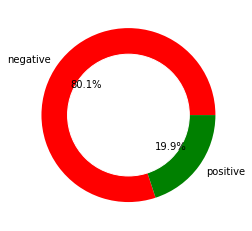

INFO - 剩余分类型变量个数：9
INFO - 剩余连续型变量个数：36
INFO - 剩余变量总数：45


无关特征删除 (791718, 45)


INFO - 剩余分类型变量个数：8
INFO - 剩余连续型变量个数：36
INFO - 剩余变量总数：44


grade,类型数：,7
subGrade,类型数：,35
employmentTitle,类型数：,246549
employmentLength,类型数：,12
purpose,类型数：,14
postCode,类型数：,933
regionCode,类型数：,51
earliesCreditLine,类型数：,720


INFO - 类别变量值合并处理,(791718, 45)
INFO - 缺失率高于0.95的变量个数为：0
INFO - 剔除缺失率高于0.95的变量：
INFO - 缺失值剔除,(791718, 45)
INFO - (791718, 45)
INFO - 同值率高于0.95的特征数量有:4
INFO - (791718, 41)
INFO - 同值率剔除,(791718, 41)
INFO - 剩余分类型变量个数：8
INFO - 剩余连续型变量个数：32
INFO - 剩余变量总数：40
INFO - 筛选出的数值特征个数：32
INFO - 方差剔除,(791718, 40)
INFO - 剩余分类型变量个数：8
INFO - 剩余连续型变量个数：32
INFO - 剩余变量总数：40
INFO - 异常值3 sigma盖帽处理
INFO - 训练集分布保存成功!
INFO - 异常值处理,(791718, 40)
INFO - 32
INFO - 剩余分类型变量个数：8
INFO - 剩余连续型变量个数：32
INFO - 剩余变量总数：40
INFO - 剔除四分位差为0的连续型变量, 剩余：26个
INFO - 四分位差剔除,(791718, 34)
INFO - 剩余分类型变量个数：8
INFO - 剩余连续型变量个数：26
INFO - 剩余变量总数：34
INFO - 缺失值填充,(791718, 34)


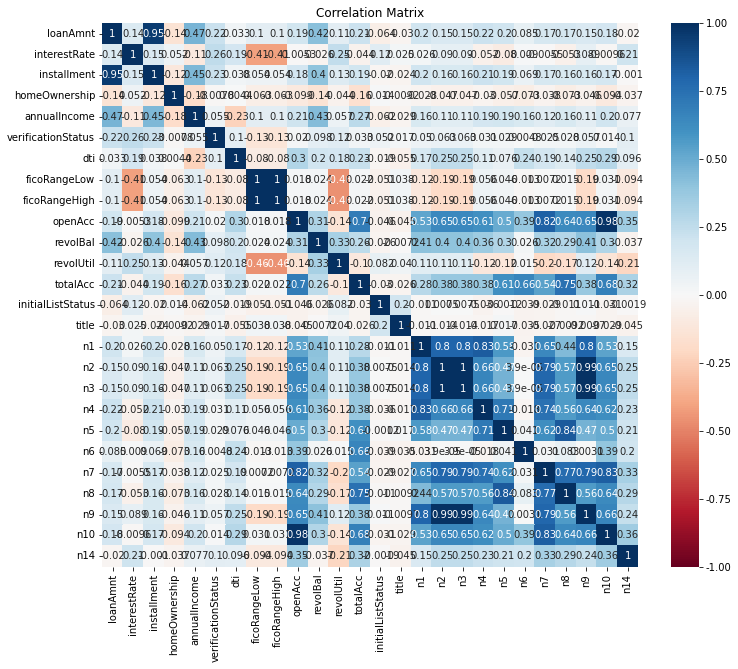

FileNotFoundError: [Errno 2] No such file or directory: './models/model_instance2/iv_df.csv'

In [3]:
mlModel.train(model_type='lgb')